# Определение эмоций в тексте

Курсовая работа, вариант 5. Губеев Илья Олегович, 3-й курс РУТ МИИТ.

Цель — сравнить три способа определения эмоций: TF-IDF + наивный Байес,
Word2Vec + небольшая нейросеть и дообучение BERT.
Вход — английский текст, выход — одна из шести эмоций.
Нейтрального класса нет: это распознавание эмоций, а не бинарная тональность.

Данные — большая версия Emotion от DAIR.AI. Она выбрана из-за объёма и наличия
категорий joy, sadness, anger, fear, love, surprise. Автоматическая разметка
может быть неоднозначной; результаты измеряют согласие с этими метками.

Работа идёт по шагам: проверка данных → очистка → лемматизация → разделение →
признаки → подбор параметров → обучение → анализ ошибок → вывод.
Ячейки запускаем сверху вниз в одном ядре. Для повторения всей очистки
сначала заново загружаем CSV: df в процессе изменяется.

## 1. Импорт библиотек

In [ ]:
import re
import copy                         # Сохранение лучших весов нейросети
import sys
from pathlib import Path
from time import perf_counter       # Измерение времени

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import emoji
import contractions
from nltk.stem import WordNetLemmatizer
from gensim.models import Word2Vec
from tqdm import tqdm               # Обычная полоса прогресса, без ipywidgets
from IPython.display import display, Markdown

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score

np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Устройство:', device)

c:\Users\Илья\.vscode\NLP-KURS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Устройство: cuda


## 2. Загрузка и первичный анализ

Сначала исследуем весь исходный CSV. DATA_LIMIT ниже ограничивает только общий
эксперимент, если нужен пробный запуск; в итоговом варианте он равен None.

In [2]:
df = pd.read_csv('emotion.csv')
raw_rows = len(df)
raw_counts = df['emotion'].value_counts()  # Сохраняем распределение до очистки
print('Размер:', df.shape)
print('Пропуски:\n', df.isna().sum())
print('Полные дубликаты:', df.duplicated().sum())
print('Пустые или пробельные тексты:', df['text'].str.strip().eq('').sum())
display(df.head())

Размер: (416809, 2)
Пропуски:
 text       0
emotion    0
dtype: int64
Полные дубликаты: 686
Пустые или пробельные тексты: 0


,text,emotion
0,i feel awful about it too because it s my job ...,sadness
1,im alone i feel awful,sadness
2,ive probably mentioned this before but i reall...,joy
3,i was feeling a little low few days back,sadness
4,i beleive that i am much more sensitive to oth...,love


emotion
joy         141067
sadness     121187
anger        57317
fear         47712
love         34554
surprise     14972
Name: count, dtype: int64

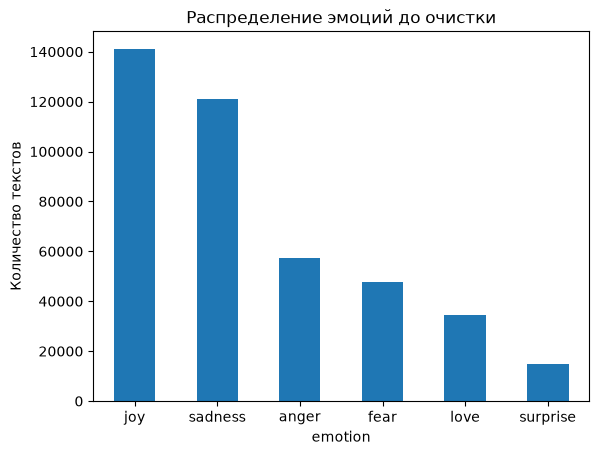

In [3]:
df_distribution = df['emotion'].value_counts()
display(df_distribution)
df_distribution.plot(kind='bar', rot=0)
plt.title('Распределение эмоций до очистки')
plt.ylabel('Количество текстов')
plt.show()

count    416809.0
mean         19.2
std          11.1
min           1.0
25%          11.0
50%          17.0
75%          25.0
max         178.0
Name: text, dtype: float64

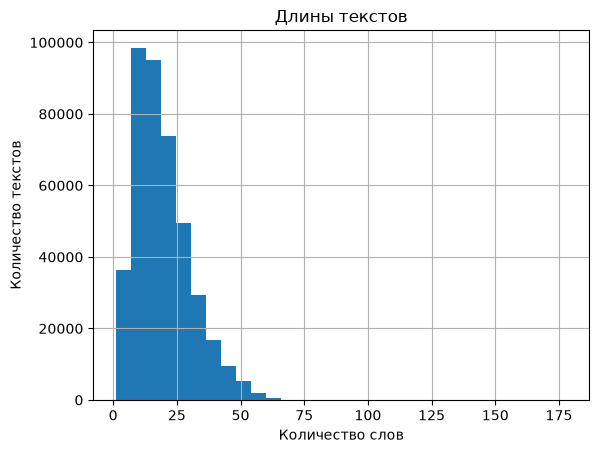

In [4]:
lengths = df['text'].str.split().str.len()
display(lengths.describe().round(1))
lengths.hist(bins=30)
plt.title('Длины текстов')
plt.xlabel('Количество слов')
plt.ylabel('Количество текстов')
plt.show()

## 3. Пропуски и дубликаты

После удаления полностью одинаковых строк оставшиеся совпадения текста
имеют разные метки. Исключаем такие группы целиком.
Это очищает неоднозначную разметку, но меняет корпус и соотношение классов.
После подготовки ещё раз проверим совпавшие представления до разделения данных.

In [5]:
rows_before = len(df)
print('Размер до очистки:', df.shape)

df = df.dropna(subset=['text', 'emotion'])
df = df.drop_duplicates()
print('После удаления пропусков и полных дубликатов:', df.shape)
print('Повторов по тексту:', df['text'].duplicated().sum())

df = df.drop_duplicates(subset='text', keep=False).copy()
rows_after_duplicates = len(df)
print('Размер после очистки:', df.shape)
print('Всего удалено строк:', rows_before - len(df))

Размер до очистки: (416809, 2)
После удаления пропусков и полных дубликатов: (416123, 2)
Повторов по тексту: 22301
Размер после очистки: (371527, 2)
Всего удалено строк: 45282


In [6]:
DATA_LIMIT = None  # Итоговый вариант: весь корпус; 3000 — пробный запуск всех моделей

# Ограничение всегда общее: сравниваем модели на одинаковых текстах.
if DATA_LIMIT is not None and DATA_LIMIT < len(df):
    df, _ = train_test_split(
        df, train_size=DATA_LIMIT, stratify=df['emotion'], random_state=42
    )
df = df.reset_index(drop=True)
print('Текстов перед подготовкой:', len(df))

Текстов перед подготовкой: 371527


## 4. Нижний регистр и обозначения эмоций

Сначала ищем обозначения в исходном text, затем меняем только clean_text.
Стоп-слова не удаляем: not, no, never и другие отрицания должны сохраниться.

In [7]:
# text сохраняем для сравнения с исходным сообщением.
df['clean_text'] = df['text'].str.lower()
df['clean_text'] = df['clean_text'].str.replace('’', "'", regex=False)
display(df[['text', 'clean_text']].head())

,text,clean_text
0,i feel awful about it too because it s my job ...,i feel awful about it too because it s my job ...
1,im alone i feel awful,im alone i feel awful
2,ive probably mentioned this before but i reall...,ive probably mentioned this before but i reall...
3,i was feeling a little low few days back,i was feeling a little low few days back
4,i beleive that i am much more sensitive to oth...,i beleive that i am much more sensitive to oth...


In [8]:
# Один словарь используем и для поиска, и для замены смайликов.
# Все ключи записаны в нижнем регистре.
smile_meanings = {
    ':)': 'smiling face', ':-)': 'smiling face',
    '=)': 'smiling face', '=-)': 'smiling face',
    ':(': 'sad face', ':-(': 'sad face',
    '=(': 'sad face', '=-(': 'sad face',
    ';)': 'winking face', ';-)': 'winking face',
    ';(': 'sad face', ';-(': 'sad face',
    ':3': 'playful face', ':-3': 'playful face',
    ':d': 'laughing face', ':-d': 'laughing face',
    ':p': 'playful face', ':-p': 'playful face',
    ':o': 'surprised face', ':-o': 'surprised face',
    ':|': 'neutral face', ':-|': 'neutral face',
    ':/': 'uneasy face', ':-/': 'uneasy face',
    ":'(": 'crying face', ":'-(": 'crying face',
    '<3': 'loving heart', '^_^': 'happy face',
    '-_-': 'unamused face', 't_t': 'crying face'
}
patterns = []
for smile in smile_meanings:
    patterns.append(re.escape(smile))
smiles_pattern = '|'.join(patterns)

In [9]:
# findall() возвращает список совпадений для каждого текста.
found_brackets = df['text'].apply(lambda text: re.findall(r'[()]', text))
found_smiles = df['text'].apply(
    lambda text: re.findall(smiles_pattern, text, flags=re.IGNORECASE)
)
found_xd = df['text'].apply(
    lambda text: re.findall(r'\bxd\b', text, flags=re.IGNORECASE)
)
found_emoji = df['text'].apply(emoji.distinct_emoji_list)

# Длина списка больше нуля — в этой строке есть совпадения.
mask_brackets = found_brackets.str.len() > 0
mask_smiles = found_smiles.str.len() > 0
mask_xd = found_xd.str.len() > 0
mask_emoji = found_emoji.str.len() > 0
print('Текстов со скобками:', mask_brackets.sum())
print('Текстов со смайликами из списка:', mask_smiles.sum())
print('Текстов с xd:', mask_xd.sum())
print('Текстов с эмодзи:', mask_emoji.sum())

Текстов со скобками: 0
Текстов со смайликами из списка: 0
Текстов с xd: 91
Текстов с эмодзи: 0


In [10]:
def replace_emotions(text):
    # Отделяем ссылки: символы :// внутри адреса не являются смайликом.
    # Скобки в шаблоне split сохраняют ссылки в нечётных позициях списка.
    parts = re.split(r'(https?://\S+|www\.\S+)', text, flags=re.IGNORECASE)
    for i in range(0, len(parts), 2):  # Обрабатываем только части вне ссылок.
        part = parts[i]
        part = re.sub(r'\bxd\b', ' laughing face ', part, flags=re.IGNORECASE)
        for smile, meaning in smile_meanings.items():
            part = part.replace(smile, ' ' + meaning + ' ')
        part = emoji.replace_emoji(
            part, replace=lambda chars, data: ' ' + data['en'].strip(':').replace('_', ' ') + ' '
        )
        parts[i] = part
    return ''.join(parts)

df['clean_text'] = df['clean_text'].apply(replace_emotions)
display(df.loc[mask_xd, ['text', 'clean_text']].head(5))

,text,clean_text
702,i think im scared of feeling shy when they ask...,i think im scared of feeling shy when they ask...
778,i am feeling a little homesick again already xd,i am feeling a little homesick again already ...
6031,is is big and loose maseis has a bold feeling ...,is is big and loose maseis has a bold feeling ...
15469,i feel so sympathetic towards plants xd a href...,i feel so sympathetic towards plants laughing...
15956,i feel i talk to myself and its awkward xd,i feel i talk to myself and its awkward laugh...


## 5. Раскрытие сокращений

contractions раскрывает обычные формы вроде don't и cant.
Формы don t и can t встречаются после удаления апострофов — добавляем их сами.
Библиотека использует словарь, поэтому неоднозначные сокращения могут раскрываться
неточно. Обрабатываем текст до удаления оставшейся пунктуации.

In [11]:
extra_forms = {
    'don t': 'do not', 'doesn t': 'does not', 'didn t': 'did not',
    'isn t': 'is not', 'aren t': 'are not',
    'wasn t': 'was not', 'weren t': 'were not',
    'haven t': 'have not', 'hasn t': 'has not', 'hadn t': 'had not',
    'can t': 'can not', 'couldn t': 'could not',
    'won t': 'will not', 'wouldn t': 'would not',
    'shan t': 'shall not', 'shouldn t': 'should not',
    'mustn t': 'must not', 'needn t': 'need not',
    'mightn t': 'might not', 'oughtn t': 'ought not'
}
for original, replacement in extra_forms.items():
    contractions.add(original, replacement)

def expand_contractions(text):
    text = contractions.fix(text)
    # Единая форма с отдельным not.
    text = re.sub(r'\bcannot\b', 'can not', text)
    return text.lower()

for text in ["don't", 'dont', 'don t', "can't", 'can t', 'isn t']:
    print(text, '→', expand_contractions(text))

don't → do not
dont → do not
don t → do not
can't → can not
can t → can not
isn t → is not


In [12]:
df['clean_text'] = df['clean_text'].apply(expand_contractions)

## 6. Поиск и очистка ссылок

В исходном корпусе могут отсутствовать полноценные http://, но сохраняться
фрагменты a href http и img src http. Ищем их по отдельным маркерам.
Не обрезаем весь текст после http: это могло бы удалить полезную часть сообщения.

In [13]:
pattern = r'\bhttps?\b|\bwww\b|\bhref\b'
mask_link_parts = df['text'].str.contains(pattern, case=False, na=False)
print('Текстов с возможными фрагментами ссылок:', mask_link_parts.sum())
with pd.option_context('display.max_colwidth', None):
    display(df.loc[mask_link_parts, ['text', 'emotion']].head(5))

Текстов с возможными фрагментами ссылок: 5065


,text,emotion
105,i feel honoured and excited to introduce the incredibly nice very well travelled and oh so stylish a href http silkyway,joy
106,i don t feel gentle a href http www,love
225,i feel a little sentimental about and will probably keep but at the end of the hour or so it took me to go through everything heres what i had a href http,sadness
307,i finally admit im feeling sorry for myself img src http community,sadness
309,i have myself fallen victim to the sheltering scheme in the homeschool world and am feeling so hopeless and lost right now this goes back to a href http www,sadness


In [14]:
def clean_links(text):
    text = re.sub(r'<[^>]+>', ' ', text)
    
    text = re.sub(
        r'https?://\S+|www\.\S+',
        ' ',
        text,
        flags=re.IGNORECASE
    )

    html_fragments = [
        'a class post count link href',
        'a target blank',
        'a href',
        'img src',
        'rel nofollow',
        'class twitter',
        'href',
        'https',
        'http',
        'www'
    ]

    for fragment in html_fragments:
        pattern = r'\b' + re.escape(fragment) + r'\b'
        text = re.sub(pattern, ' ', text, flags=re.IGNORECASE)

    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [15]:
# Сохраняем состояние до очистки ссылок для отдельного эксперимента.
df['before_links_text'] = df['clean_text']
df['clean_text'] = df['clean_text'].apply(clean_links)
links_changed = df['before_links_text'] != df['clean_text']

remaining = df['clean_text'].str.contains(
    r'\bhttps?\b|\bwww\b|\bhref\b', case=False, na=False
)
print('Текстов с оставшимися маркерами:', remaining.sum())
with pd.option_context('display.max_colwidth', None):
    display(df.loc[mask_link_parts, ['text', 'clean_text']].head(5))

# BERT получает текст до лемматизации и объединения отрицаний.
# Служебные фрагменты уже удалены, эмоциональные обозначения заменены.
df['bert_text'] = df['clean_text']

Текстов с оставшимися маркерами: 0


,text,clean_text
105,i feel honoured and excited to introduce the incredibly nice very well travelled and oh so stylish a href http silkyway,i feel honoured and excited to introduce the incredibly nice very well travelled and oh so stylish silkyway
106,i don t feel gentle a href http www,i do not feel gentle
225,i feel a little sentimental about and will probably keep but at the end of the hour or so it took me to go through everything heres what i had a href http,i feel a little sentimental about and will probably keep but at the end of the hour or so it took me to go through everything here is what i had
307,i finally admit im feeling sorry for myself img src http community,i finally admit i am feeling sorry for myself community
309,i have myself fallen victim to the sheltering scheme in the homeschool world and am feeling so hopeless and lost right now this goes back to a href http www,i have myself fallen victim to the sheltering scheme in the homeschool world and am feeling so hopeless and lost right now this goes back to


Названия сайтов могут остаться: границы адресов в корпусе потеряны,
и обычное слово не всегда можно отличить от части адреса.
В отдельном опыте ниже проверим пользу именно этой очистки по validation Macro-F1.

## 7. Символы, пробелы и лемматизация

Для классических признаков оставляем английские буквы и пробелы.
Лемматизация приводит слова к словарной форме: cars → car, was → be.
Для английского используем WordNet и учитываем часть речи.

In [16]:
def clean_letters(text):
    # Заменяем разделители пробелом: good/bad не превратится в goodbad.
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_text'] = df['clean_text'].apply(clean_letters)
print('Пустых текстов после очистки:', df['clean_text'].eq('').sum())
display(df[['text', 'clean_text']].head())

Пустых текстов после очистки: 0


,text,clean_text
0,i feel awful about it too because it s my job ...,i feel awful about it too because it s my job ...
1,im alone i feel awful,i am alone i feel awful
2,ive probably mentioned this before but i reall...,i have probably mentioned this before but i re...
3,i was feeling a little low few days back,i was feeling a little low few days back
4,i beleive that i am much more sensitive to oth...,i beleive that i am much more sensitive to oth...


In [17]:
lemmatizer = WordNetLemmatizer()
# Сначала используем установленные ресурсы — без обращения в интернет.
# LookupError означает, что нужного словаря или модели ещё нет.

# J — прилагательное, V — глагол, N — существительное, R — наречие.
pos_map = {'J': 'a', 'V': 'v', 'N': 'n', 'R': 'r'}

def lemmatize_text(text):
    words = text.split()
    tagged_words = nltk.pos_tag(words, lang='eng')
    lemmas = []
    for word, tag in tagged_words:
        # Если часть речи неизвестна, считаем слово существительным.
        pos = pos_map.get(tag[0], 'n')
        lemmas.append(lemmatizer.lemmatize(word, pos=pos))
    return ' '.join(lemmas)

tqdm.pandas(desc='Лемматизация')
df['lemma_text'] = df['clean_text'].progress_apply(lemmatize_text)
display(df[['clean_text', 'lemma_text']].head())

Лемматизация: 100%|██████████| 371527/371527 [04:08<00:00, 1492.35it/s]


,clean_text,lemma_text
0,i feel awful about it too because it s my job ...,i feel awful about it too because it s my job ...
1,i am alone i feel awful,i be alone i feel awful
2,i have probably mentioned this before but i re...,i have probably mention this before but i real...
3,i was feeling a little low few days back,i be feel a little low few day back
4,i beleive that i am much more sensitive to oth...,i beleive that i be much more sensitive to oth...


## 8. Отрицания как отдельные признаки

Сохраняем not и дополнительно связываем его с ближайшим содержательным словом:
not very happy → not very not_happy.
Пропускаем несколько связок/усилителей, союз прерывает поиск.
Смотрим максимум четыре слова вперёд. Это эвристика: сложные отрицания и ирония
могут обрабатываться неточно. Потерянную ранее пунктуацию корпуса восстановить нельзя.

In [18]:
negations = {'not', 'no', 'never', 'neither', 'nor', 'without'}
skip_words = {'a', 'an', 'the', 'very', 'really', 'so', 'too', 'quite',
              'feel', 'be', 'do', 'seem', 'look', 'much', 'more', 'just'}
boundaries = {'but', 'however', 'although', 'though', 'yet', 'and', 'or'}

def join_negations(text):
    words = text.split()
    result = words.copy()  # Само отрицание остаётся в тексте.
    for i, word in enumerate(words):
        if word in negations:
            for j in range(i + 1, min(i + 5, len(words))):
                if words[j] in boundaries or words[j] in negations:
                    break
                if words[j] not in skip_words:
                    result[j] = word + '_' + words[j]
                    break
    return ' '.join(result)

print(join_negations('i be not very happy but i like it'))
df['prepared_text'] = df['lemma_text'].apply(join_negations)

i be not very not_happy but i like it


In [19]:
# После обработки разные исходные тексты могли стать одинаковыми.
# Убираем совпадения до разделения, чтобы не получить утечку данных.
before = len(df)
df = df[df['prepared_text'].ne('')].copy()
df = df.drop_duplicates(subset=['prepared_text', 'emotion'])
df = df.drop_duplicates(subset='prepared_text', keep=False).reset_index(drop=True)
print('Исключено пустых, повторов и конфликтующих текстов:', before - len(df))
print('Текстов после всей подготовки:', len(df))
display(df[['text', 'clean_text', 'prepared_text', 'bert_text']].head())

Исключено пустых, повторов и конфликтующих текстов: 1959
Текстов после всей подготовки: 369568


,text,clean_text,prepared_text,bert_text
0,i feel awful about it too because it s my job ...,i feel awful about it too because it s my job ...,i feel awful about it too because it s my job ...,i feel awful about it too because it s my job ...
1,im alone i feel awful,i am alone i feel awful,i be alone i feel awful,i am alone i feel awful
2,ive probably mentioned this before but i reall...,i have probably mentioned this before but i re...,i have probably mention this before but i real...,i have probably mentioned this before but i re...
3,i was feeling a little low few days back,i was feeling a little low few days back,i be feel a little low few day back,i was feeling a little low few days back
4,i beleive that i am much more sensitive to oth...,i beleive that i am much more sensitive to oth...,i beleive that i be much more sensitive to oth...,i beleive that i am much more sensitive to oth...


## 9. Train, validation и test

80% текстов — обучение, 10% — выбор параметров и эпох, 10% — итоговая проверка.
Разделение общее для всех моделей. Словари и масштабирование обучаются только по train.
Стратификация сохраняет доли классов, но не делает их равными.

In [20]:
train_df, temp_df = train_test_split(
    df, 
    test_size=0.2, 
    stratify=df['emotion'], 
    random_state=42
    )

val_df, test_df = train_test_split(
    temp_df, 
    test_size=0.5, 
    stratify=temp_df['emotion'], 
    random_state=42
    )

encoder = LabelEncoder()

y_train = encoder.fit_transform(train_df['emotion'])
y_val = encoder.transform(val_df['emotion'])
y_test = encoder.transform(test_df['emotion'])

class_names = encoder.classes_
class_count = len(class_names)

class_weights = torch.tensor(
    compute_class_weight('balanced', classes=np.arange(class_count), y=y_train),
    dtype=torch.float32, device=device
)
print('Train / validation / test:', len(train_df), len(val_df), len(test_df))
print(dict(enumerate(class_names)))

Train / validation / test: 295654 36957 36957
{0: 'anger', 1: 'fear', 2: 'joy', 3: 'love', 4: 'sadness', 5: 'surprise'}


          До очистки  После подготовки   Train  Validation   Test
emotion                                                          
anger          57317             52032   41625        5204   5203
fear           47712             39346   31477        3934   3935
joy           141067            128741  102993       12874  12874
love           34554             24262   19410        2426   2426
sadness       121187            115392   92313       11539  11540
surprise       14972              9795    7836         980    979
          До очистки  После подготовки  Train  Validation   Test
emotion                                                         
anger          13.75             14.08  14.08       14.08  14.08
fear           11.45             10.65  10.65       10.64  10.65
joy            33.84             34.84  34.84       34.84  34.84
love            8.29              6.56   6.57        6.56   6.56
sadness        29.07             31.22  31.22       31.22  31.23
surprise        3

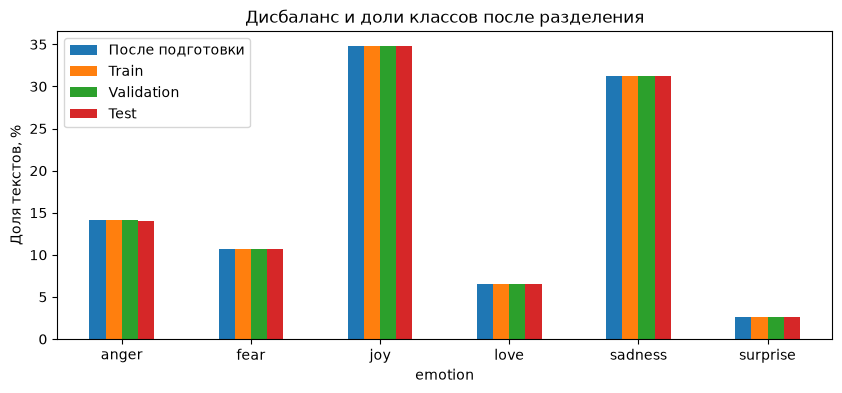

In [21]:
counts = pd.DataFrame({
    'До очистки': raw_counts,
    'После подготовки': df['emotion'].value_counts(),
    'Train': train_df['emotion'].value_counts(),
    'Validation': val_df['emotion'].value_counts(),
    'Test': test_df['emotion'].value_counts()
}).reindex(class_names)
print(counts)

shares = counts.div(counts.sum(), axis=1) * 100
print(shares.round(2))
shares[['После подготовки', 'Train', 'Validation', 'Test']].plot.bar(figsize=(10, 4), rot=0)
plt.ylabel('Доля текстов, %')
plt.title('Дисбаланс и доли классов после разделения')
plt.show()


Вес класса равен N / (K × N_c), где N — число обучающих примеров,
K — число классов, N_c — число примеров данной эмоции.
В нейросетях ошибка на редком классе получает больший вес.
Validation и test не балансируем. Основная метрика — Macro-F1,
которая одинаково учитывает все классы. Balanced accuracy — средний Recall классов.

## 11. TF-IDF + наивный Байес: baseline

TF-IDF отражает частоту слова в тексте и его распространённость в train.
Подчёркивание сохраняем: not_happy должно остаться одним признаком.
Байес оценивает вероятности признаков внутри классов со сглаживанием alpha.
Выбираем alpha из трёх значений по validation Macro-F1.
Общий baseline ниже — лучший из этих трёх вариантов.

In [ ]:
tfidf_rows = []
best_tfidf_f1 = -1

start = perf_counter()

for max_features in [30000, 50000, 100000]:
    for min_df in [2, 3, 5]:
        for ngram_range in [(1, 1), (1, 2)]:
            for sublinear_tf in [True, False]:

                vectorizer = TfidfVectorizer(
                    max_features=max_features,
                    min_df=min_df,
                    lowercase=False,
                    ngram_range=ngram_range,
                    sublinear_tf=sublinear_tf,
                    token_pattern=r'(?u)\b[a-z]+(?:_[a-z]+)*\b',
                    dtype=np.float32
                )

                x_train = vectorizer.fit_transform(train_df['prepared_text'])
                x_val = vectorizer.transform(val_df['prepared_text'])

                model = MultinomialNB(alpha=0.5)
                model.fit(x_train, y_train)

                prediction = model.predict(x_val)

                macro_f1 = f1_score(y_val, prediction, average='macro')
                weighted_f1 = f1_score(y_val, prediction, average='weighted')
                accuracy = accuracy_score(y_val, prediction)
                precision = precision_score(y_val, prediction, average='macro', zero_division=0)
                recall = recall_score(y_val, prediction, average='macro', zero_division=0)

                tfidf_rows.append({
                    'max_features': max_features,
                    'min_df': min_df,
                    'ngram_range': ngram_range,
                    'sublinear_tf': sublinear_tf,
                    'Accuracy': accuracy,
                    'Macro-F1': macro_f1,
                    'Weighted-F1': weighted_f1,
                    'Macro-Precision': precision,
                    'Macro-Recall': recall
                })

                if macro_f1 > best_tfidf_f1:
                    best_tfidf_f1 = macro_f1
                    best_tfidf_params = {
                        'max_features': max_features,
                        'min_df': min_df,
                        'ngram_range': ngram_range,
                        'sublinear_tf': sublinear_tf
                    }

tfidf_time = perf_counter() - start

tfidf_search = pd.DataFrame(tfidf_rows)

display(
    tfidf_search.sort_values('Macro-F1', ascending=False).round(4)
)

print('Лучшие параметры:', best_tfidf_params)
print('Лучший Macro-F1:', round(best_tfidf_f1, 4))
print('Время подбора:', round(tfidf_time, 2), 'сек.')

,max_features,min_df,ngram_range,sublinear_tf,Accuracy,Macro-F1,Weighted-F1,Macro-Precision,Macro-Recall
6,30000,3,"(1, 2)",True,0.8806,0.8180,0.8762,0.9234,0.7622
2,30000,2,"(1, 2)",True,0.8806,0.8179,0.8763,0.9234,0.7621
10,30000,5,"(1, 2)",True,0.8806,0.8179,0.8762,0.9235,0.7621
7,30000,3,"(1, 2)",False,0.8790,0.8151,0.8745,0.9238,0.7586
3,30000,2,"(1, 2)",False,0.8790,0.8150,0.8744,0.9238,0.7585
11,30000,5,"(1, 2)",False,0.8790,0.8150,0.8744,0.9238,0.7585
22,50000,5,"(1, 2)",True,0.8825,0.8101,0.8773,0.9262,0.7544
18,50000,3,"(1, 2)",True,0.8825,0.8097,0.8772,0.9259,0.7541
14,50000,2,"(1, 2)",True,0.8824,0.8097,0.8771,0.9259,0.7540
23,50000,5,"(1, 2)",False,0.8808,0.8078,0.8755,0.9254,0.7517


Лучшие параметры: {'max_features': 30000, 'min_df': 3, 'ngram_range': (1, 2), 'sublinear_tf': True}
Лучший Macro-F1: 0.818
Время подбора: 285.25 сек.


In [23]:
# Одни и те же метрики используем в подборе и итоговой проверке.
def get_metrics(real, predicted):
    return {
        'Accuracy': accuracy_score(real, predicted),
        'Macro-Precision': precision_score(real, predicted, average='macro', zero_division=0),
        'Macro-Recall': recall_score(real, predicted, average='macro', zero_division=0),
        'Macro-F1': f1_score(real, predicted, average='macro', zero_division=0),
        'Weighted-Precision': precision_score(real, predicted, average='weighted', zero_division=0),
        'Weighted-Recall': recall_score(real, predicted, average='weighted', zero_division=0),
        'Weighted-F1': f1_score(real, predicted, average='weighted', zero_division=0),
        'Balanced accuracy': balanced_accuracy_score(real, predicted)
    }

In [24]:
start = perf_counter()
# Создаём признаки с лучшими найденными настройками.
vectorizer = TfidfVectorizer(
    **best_tfidf_params,
    lowercase=False,
    token_pattern=r'(?u)\b[a-z]+(?:_[a-z]+)*\b',
    dtype=np.float32
)

x_train_tfidf = vectorizer.fit_transform(train_df['prepared_text'])
x_val_tfidf = vectorizer.transform(val_df['prepared_text'])
x_test_tfidf = vectorizer.transform(test_df['prepared_text'])

print('Размер train:', x_train_tfidf.shape)
tfidf_build_time = perf_counter() - start

Размер train: (295654, 30000)


In [25]:
nb_rows = []
best_nb_f1 = -1

start = perf_counter()

for alpha in [0.1, 0.5, 1.0]:
    model = MultinomialNB(alpha=alpha)

    model.fit(x_train_tfidf, y_train)

    prediction = model.predict(x_val_tfidf)

    score = f1_score(y_val, prediction, average='macro')

    nb_rows.append({
        'alpha': alpha,
        'Macro-F1 (val)': score
    })

    if score > best_nb_f1:
        best_nb_f1 = score
        best_alpha = alpha

nb_time = perf_counter() - start

nb_search = pd.DataFrame(nb_rows)
display(nb_search.round(4))

print('Выбрано alpha:', best_alpha)
print('Лучший Macro-F1:', round(best_nb_f1, 4))
print('Время подбора:', round(nb_time, 2), 'сек.')

,alpha,Macro-F1 (val)
0,0.1,0.8422
1,0.5,0.8180
2,1.0,0.7802


Выбрано alpha: 0.1
Лучший Macro-F1: 0.8422
Время подбора: 0.36 сек.


In [26]:
# Твою ячейку подбора alpha выше сохраняем.
# Здесь получаем остальные метрики каждого варианта и сохраняем выбранную модель.
nb_metrics_rows = []
start = perf_counter()

for alpha in [0.1, 0.5, 1.0]:
    candidate = MultinomialNB(alpha=alpha)
    candidate.fit(x_train_tfidf, y_train)
    prediction = candidate.predict(x_val_tfidf)

    row = {'alpha': alpha}
    row.update(get_metrics(y_val, prediction))
    nb_metrics_rows.append(row)

    if alpha == best_alpha:
        model_nb = candidate

nb_details_time = perf_counter() - start
display(pd.DataFrame(nb_metrics_rows).round(4))

,alpha,Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Weighted-Precision,Weighted-Recall,Weighted-F1,Balanced accuracy
0,0.1,0.8895,0.9250,0.7913,0.8422,0.8957,0.8895,0.8865,0.7913
1,0.5,0.8806,0.9234,0.7622,0.8180,0.8889,0.8806,0.8762,0.7622
2,1.0,0.8675,0.9211,0.7215,0.7802,0.8793,0.8675,0.8603,0.7215


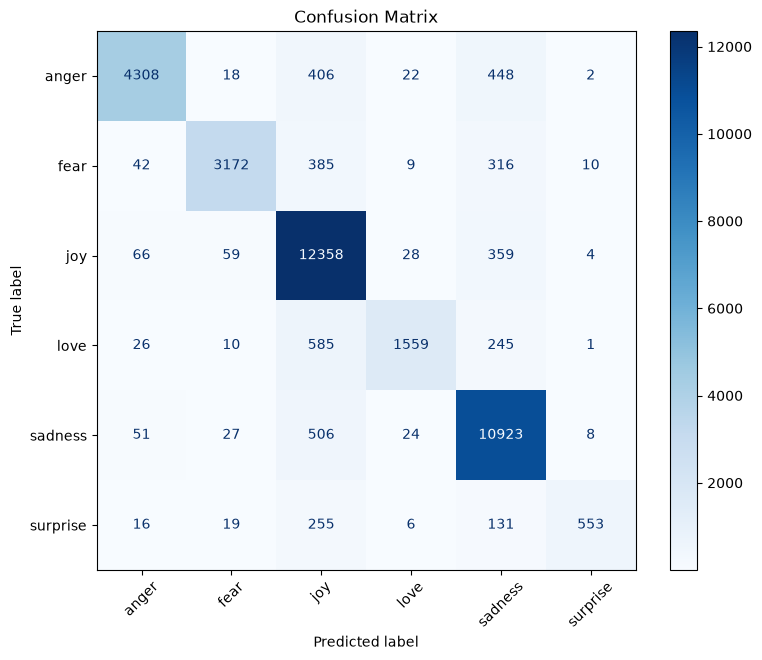

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, model_nb.predict(x_val_tfidf))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap='Blues', xticks_rotation=45)
plt.title('Confusion Matrix')
plt.show()

## 12. Word2Vec

Обучаем Word2Vec только на train. Размер вектора и окно подберём ниже.
Вектор текста — среднее векторов его известных слов. Это упрощение:
при усреднении теряется порядок слов.

In [29]:
# Разбиваем обучающие тексты на слова для Word2Vec.
tokens_train = [text.split() for text in train_df['prepared_text']]

# Вектор текста — среднее векторов известных слов.
def text_vector(text):
    vectors = []

    for word in text.split():
        if word in word2vec.wv:
            vectors.append(word2vec.wv[word])

    if len(vectors) == 0:
        return np.zeros(word2vec.vector_size, dtype=np.float32)

    return np.mean(vectors, axis=0)

## 13. Нейросеть для Word2Vec

У сети один скрытый слой. Она получает усреднённый вектор текста и выдаёт
оценку каждого из шести классов. Для обучения используем CrossEntropyLoss
и AdamW. Веса классов помогают учитывать дисбаланс.

In [30]:
BATCH_SIZE = 256
SEARCH_SIZE = 10000   # Часть train для сети при подборе
SEARCH_EPOCHS = 5
NN_EPOCHS = 30        # Верхняя граница; сохраняем лучшую эпоху
NN_PATIENCE = 3       # Остановиться после трёх эпох без улучшения validation F1

In [31]:
def evaluate_nn(model, features, labels):
    dataset = TensorDataset(torch.from_numpy(features), torch.tensor(labels))
    loader = DataLoader(dataset, batch_size=256, shuffle=False)
    predictions = []
    total_loss = 0

    model.eval()  # При проверке Dropout выключен.
    with torch.no_grad():
        for batch_x, batch_y in loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            outputs = model(batch_x)
            total_loss += nn.functional.cross_entropy(outputs, batch_y, reduction='sum').item()
            predictions.extend(outputs.argmax(dim=1).cpu().tolist())

    return np.array(predictions), total_loss / len(dataset)

In [32]:
def train_nn(x_train, y_train, x_val, y_val, hidden_size, learning_rate, epochs):
    torch.manual_seed(42)
    model = nn.Sequential(
        nn.Linear(x_train.shape[1], hidden_size),
        nn.ELU(),
        nn.Dropout(0.4),
        nn.Linear(hidden_size, class_count)
    ).to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    dataset = TensorDataset(torch.from_numpy(x_train), torch.tensor(y_train))
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)
    y_train_labels, y_val_labels = y_train, y_val
    history = []
    best_score = -1
    bad_epochs = 0

    for epoch in range(epochs):
        model.train()
        for batch_x, batch_y in loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()             # Убираем старые градиенты.
            outputs = model(batch_x)          # Получаем ответы сети.
            loss = criterion(outputs, batch_y) # Считаем ошибку.
            loss.backward()                   # Находим градиенты.
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()                  # Меняем веса сети.

        train_pred, train_loss = evaluate_nn(model, x_train, y_train)
        val_pred, val_loss = evaluate_nn(model, x_val, y_val)
        train_f1 = f1_score(y_train, train_pred, average='macro', zero_division=0)
        val_f1 = f1_score(y_val, val_pred, average='macro', zero_division=0)
        history.append({
            'epoch': epoch + 1,
            'train_loss': train_loss, 'val_loss': val_loss,
            'train_accuracy': accuracy_score(y_train_labels, train_pred),
            'val_accuracy': accuracy_score(y_val_labels, val_pred),
            'train_precision': precision_score(y_train_labels, train_pred, average='macro', zero_division=0),
            'val_precision': precision_score(y_val_labels, val_pred, average='macro', zero_division=0),
            'train_recall': recall_score(y_train_labels, train_pred, average='macro', zero_division=0),
            'val_recall': recall_score(y_val_labels, val_pred, average='macro', zero_division=0),
            'train_f1': train_f1, 'val_f1': val_f1,
            'train_weighted_f1': f1_score(y_train_labels, train_pred, average='weighted', zero_division=0),
            'val_weighted_f1': f1_score(y_val_labels, val_pred, average='weighted', zero_division=0)
        })
        last = history[-1]
        print(f"Эпоха {epoch + 1}: val loss={val_loss:.3f}, "
              f"P={last['val_precision']:.3f}, R={last['val_recall']:.3f}, F1={val_f1:.3f}", flush=True)

        if val_f1 > best_score:
            best_score = val_f1
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= NN_PATIENCE:
                print('Ранняя остановка: validation F1 больше не улучшается.')
                break

    model.load_state_dict(best_weights)
    model.best_epoch = best_epoch
    model.eval()
    print('Восстановлена лучшая эпоха:', best_epoch)
    return model, pd.DataFrame(history), best_score

## 14. Подбор Word2Vec и нейросети

Пробуем размер вектора 100/200 и окно 3/5. Для каждого варианта Word2Vec
сравниваем 64/128 нейронов и learning rate 0.001/0.0005 — всего 16 сочетаний.
Выбираем лучшее по Macro-F1 на validation. Word2Vec обучается на всём train,
а сеть во время подбора — на части train. Затем итоговая связка обучается
на всём train. Test для выбора параметров не используется.

In [33]:
# Берём одну и ту же часть train для всех вариантов сети.
search_indices = np.arange(len(y_train))

if SEARCH_SIZE < len(y_train):
    search_indices, _ = train_test_split(
        search_indices, train_size=SEARCH_SIZE, stratify=y_train, random_state=42
    )

nn_rows = []
start = perf_counter()

for vector_size in [100, 200]:
    for window in [3, 5]:
        print('Word2Vec: размер вектора =', vector_size, ', окно =', window)

        # Словарь и векторы слов строим только по train.
        word2vec = Word2Vec(
            sentences=tokens_train, vector_size=vector_size, window=window,
            min_count=2, sg=1, epochs=5, workers=1, seed=42
        )

        search_texts = train_df['prepared_text'].iloc[search_indices]
        x_search = np.vstack([text_vector(text) for text in search_texts])
        x_val_w2v = np.vstack([text_vector(text) for text in val_df['prepared_text']])

        # При подборе масштабируем по той части train, на которой учится сеть.
        scaler = StandardScaler()
        x_search = scaler.fit_transform(x_search).astype(np.float32)
        x_val_w2v = scaler.transform(x_val_w2v).astype(np.float32)

        for hidden_size in [64, 128]:
            for learning_rate in [0.001, 0.0005]:
                print('Нейронов:', hidden_size, ', learning rate:', learning_rate)

                search_model, _, score = train_nn(
                    x_search, y_train[search_indices], x_val_w2v, y_val,
                    hidden_size, learning_rate, SEARCH_EPOCHS
                )

                prediction, _ = evaluate_nn(search_model, x_val_w2v, y_val)

                row = {
                    'vector_size': vector_size,
                    'window': window,
                    'hidden_size': hidden_size,
                    'learning_rate': learning_rate
                }
                row.update(get_metrics(y_val, prediction))
                nn_rows.append(row)
                del search_model

nn_search_time = perf_counter() - start
nn_search = pd.DataFrame(nn_rows).sort_values('Macro-F1', ascending=False)
display(nn_search.round(4))

best_vector_size = int(nn_search.iloc[0]['vector_size'])
best_window = int(nn_search.iloc[0]['window'])
best_hidden = int(nn_search.iloc[0]['hidden_size'])
best_lr = float(nn_search.iloc[0]['learning_rate'])
print('Выбрано:', best_vector_size, best_window, best_hidden, best_lr)

Word2Vec: размер вектора = 100 , окно = 3
Нейронов: 64 , learning rate: 0.001
Эпоха 1: val loss=1.465, P=0.441, R=0.507, F1=0.424
Эпоха 2: val loss=1.259, P=0.484, R=0.564, F1=0.482
Эпоха 3: val loss=1.164, P=0.501, R=0.586, F1=0.504
Эпоха 4: val loss=1.117, P=0.510, R=0.596, F1=0.516
Эпоха 5: val loss=1.102, P=0.513, R=0.604, F1=0.520
Восстановлена лучшая эпоха: 5
Нейронов: 64 , learning rate: 0.0005
Эпоха 1: val loss=1.614, P=0.370, R=0.405, F1=0.335
Эпоха 2: val loss=1.467, P=0.441, R=0.510, F1=0.426
Эпоха 3: val loss=1.349, P=0.469, R=0.546, F1=0.462
Эпоха 4: val loss=1.267, P=0.484, R=0.566, F1=0.482
Эпоха 5: val loss=1.210, P=0.494, R=0.580, F1=0.496
Восстановлена лучшая эпоха: 5
Нейронов: 128 , learning rate: 0.001
Эпоха 1: val loss=1.340, P=0.464, R=0.532, F1=0.452
Эпоха 2: val loss=1.170, P=0.497, R=0.579, F1=0.500
Эпоха 3: val loss=1.116, P=0.511, R=0.598, F1=0.517
Эпоха 4: val loss=1.083, P=0.518, R=0.606, F1=0.527
Эпоха 5: val loss=1.077, P=0.521, R=0.612, F1=0.529
Восстано

,vector_size,window,hidden_size,learning_rate,Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Weighted-Precision,Weighted-Recall,Weighted-F1,Balanced accuracy
14,200,5,128,0.0010,0.6655,0.5771,0.6787,0.5991,0.7236,0.6655,0.6812,0.6787
10,200,3,128,0.0010,0.6470,0.5606,0.6596,0.5782,0.7131,0.6470,0.6650,0.6596
12,200,5,64,0.0010,0.6416,0.5612,0.6670,0.5779,0.7166,0.6416,0.6605,0.6670
15,200,5,128,0.0005,0.6376,0.5557,0.6590,0.5722,0.7099,0.6376,0.6559,0.6590
8,200,3,64,0.0010,0.6287,0.5492,0.6510,0.5633,0.7066,0.6287,0.6484,0.6510
11,200,3,128,0.0005,0.6236,0.5428,0.6410,0.5561,0.6986,0.6236,0.6427,0.6410
13,200,5,64,0.0005,0.6082,0.5354,0.6360,0.5452,0.6980,0.6082,0.6292,0.6360
6,100,5,128,0.0010,0.6043,0.5312,0.6308,0.5411,0.6904,0.6043,0.6261,0.6308
4,100,5,64,0.0010,0.5934,0.5236,0.6249,0.5317,0.6855,0.5934,0.6161,0.6249
9,200,3,64,0.0005,0.5968,0.5229,0.6168,0.5306,0.6863,0.5968,0.6179,0.6168


Выбрано: 200 5 128 0.001


In [34]:
# Заново обучаем Word2Vec с выбранными параметрами на всём train.
start = perf_counter()
word2vec = Word2Vec(
    sentences=tokens_train, vector_size=best_vector_size, window=best_window,
    min_count=2, sg=1, epochs=5, workers=1, seed=42
)

x_train_w2v = np.vstack([text_vector(text) for text in train_df['prepared_text']])
x_val_w2v = np.vstack([text_vector(text) for text in val_df['prepared_text']])
x_test_w2v = np.vstack([text_vector(text) for text in test_df['prepared_text']])

# Для итоговой модели рассчитываем масштаб только по полному train.
scaler = StandardScaler()
x_train_w2v = scaler.fit_transform(x_train_w2v).astype(np.float32)
x_val_w2v = scaler.transform(x_val_w2v).astype(np.float32)
x_test_w2v = scaler.transform(x_test_w2v).astype(np.float32)
word2vec_time = perf_counter() - start

start = perf_counter()
model_w2v, history_w2v, _ = train_nn(
    x_train_w2v, y_train, x_val_w2v, y_val, best_hidden, best_lr, NN_EPOCHS
)
nn_time = perf_counter() - start
print(model_w2v)

Эпоха 1: val loss=0.855, P=0.603, R=0.725, F1=0.628
Эпоха 2: val loss=0.795, P=0.622, R=0.737, F1=0.651
Эпоха 3: val loss=0.765, P=0.631, R=0.750, F1=0.664
Эпоха 4: val loss=0.739, P=0.644, R=0.760, F1=0.676
Эпоха 5: val loss=0.731, P=0.646, R=0.767, F1=0.680
Эпоха 6: val loss=0.708, P=0.654, R=0.770, F1=0.687
Эпоха 7: val loss=0.713, P=0.654, R=0.778, F1=0.687
Эпоха 8: val loss=0.687, P=0.663, R=0.777, F1=0.697
Эпоха 9: val loss=0.675, P=0.669, R=0.784, F1=0.704
Эпоха 10: val loss=0.675, P=0.668, R=0.786, F1=0.703
Эпоха 11: val loss=0.667, P=0.670, R=0.786, F1=0.704
Эпоха 12: val loss=0.670, P=0.666, R=0.787, F1=0.701
Эпоха 13: val loss=0.647, P=0.683, R=0.793, F1=0.718
Эпоха 14: val loss=0.655, P=0.674, R=0.794, F1=0.708
Эпоха 15: val loss=0.637, P=0.687, R=0.794, F1=0.723
Эпоха 16: val loss=0.653, P=0.676, R=0.796, F1=0.711
Эпоха 17: val loss=0.628, P=0.689, R=0.798, F1=0.724
Эпоха 18: val loss=0.617, P=0.693, R=0.798, F1=0.728
Эпоха 19: val loss=0.636, P=0.683, R=0.799, F1=0.719
Эп

## 15. DistilBERT: подготовка текстов

DistilBERT — готовая языковая модель. Мы дообучаем её веса и выходной слой
на нашей задаче с шестью эмоциями. Она получает `bert_text`: текст без
лемматизации и составных признаков вроде `not_happy`.

Токенизатор переводит текст в номера токенов и создаёт attention mask,
чтобы модель отличала текст от заполнения. Ограничение — 64 токена.
При первом запуске модель скачивается из интернета в виртуальное окружение.

In [35]:
MODEL_NAME = 'distilbert/distilbert-base-uncased'
MAX_LENGTH = 64
BERT_BATCH_SIZE = 8
BERT_EPOCHS = 6      # Верхняя граница, а не обязательное число эпох
BERT_PATIENCE = 2   # Две эпохи без улучшения validation F1

cache_path = Path.cwd() / 'coursework_cache'
cache_path.mkdir(exist_ok=True)

In [36]:
# Загружаем токенизатор выбранного DistilBERT.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, cache_dir=str(cache_path / 'huggingface'))

# Переводим тексты и ответы в формат, подходящий для PyTorch.
def bert_dataset(texts, labels):
    tokens = tokenizer(list(texts), padding='max_length', truncation=True,
                       max_length=MAX_LENGTH, return_tensors='pt')
    return TensorDataset(tokens['input_ids'], tokens['attention_mask'],
                         torch.tensor(np.asarray(labels), dtype=torch.long))

lengths = tokenizer(train_df['bert_text'].tolist(), truncation=False)['input_ids']
long_texts = sum(len(ids) > MAX_LENGTH for ids in lengths)
print('Текстов длиннее', MAX_LENGTH, 'токенов:', long_texts, 'из', len(lengths))

c:\Users\Илья\.vscode\NLP-KURS\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Илья\.vscode\NLP-KURS\.venv\coursework_cache\huggingface\models--distilbert--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Текстов длиннее 64 токенов: 635 из 295654


## 16. Подбор и дообучение DistilBERT

Для подбора скорости обучения проверяем 0.00002 и 0.00005 на 600 текстах
из train. Каждый вариант обучается одну эпоху и проверяется на validation.
Затем заново загружаем исходный DistilBERT и обучаем на всём train
с выбранной скоростью. Такой небольшой подбор выбран ради времени на CPU.

Для каждой эпохи сохраняем Macro-F1 и потери train/validation.
Для итоговой проверки возвращаем веса лучшей эпохи по validation Macro-F1.

In [37]:
# Для подбора берём небольшие фиксированные части train и validation.
bert_search_train = train_df
if len(train_df) > 600:
    bert_search_train, _ = train_test_split(
        train_df, train_size=600, stratify=train_df['emotion'], random_state=42
    )

bert_search_val = val_df
if len(val_df) > 500:
    bert_search_val, _ = train_test_split(
        val_df, train_size=500, stratify=val_df['emotion'], random_state=42
    )

bert_search_train_data = bert_dataset(
    bert_search_train['bert_text'], encoder.transform(bert_search_train['emotion'])
)
bert_search_val_data = bert_dataset(
    bert_search_val['bert_text'], encoder.transform(bert_search_val['emotion'])
)

# Полный validation остаётся для итогового обучения и сравнения моделей.
bert_val_data = bert_dataset(val_df['bert_text'], y_val)
print('Подбор DistilBERT, train / validation:',
      len(bert_search_train_data), len(bert_search_val_data))

Подбор DistilBERT, train / validation: 600 500


In [38]:
def evaluate_bert(model, dataset):
    loader = DataLoader(dataset, batch_size=BERT_BATCH_SIZE, shuffle=False)
    predictions, labels = [], []
    total_loss = 0

    model.eval()
    with torch.no_grad():
        for ids, mask, batch_y in loader:
            ids, mask, batch_y = ids.to(device), mask.to(device), batch_y.to(device)
            outputs = model(input_ids=ids, attention_mask=mask).logits
            total_loss += nn.functional.cross_entropy(outputs, batch_y, reduction='sum').item()
            predictions.extend(outputs.argmax(dim=1).cpu().tolist())
            labels.extend(batch_y.cpu().tolist())

    score = f1_score(labels, predictions, average='macro', zero_division=0)
    return np.array(predictions), total_loss / len(dataset), score

In [39]:
def train_bert(train_data, val_data, learning_rate, epochs):
    torch.manual_seed(42)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=class_count, cache_dir=str(cache_path / 'huggingface')
    ).to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    loader = DataLoader(train_data, batch_size=BERT_BATCH_SIZE, shuffle=True)
    y_train_labels = train_data.tensors[2].numpy()
    y_val_labels = val_data.tensors[2].numpy()
    history = []
    best_score = -1
    bad_epochs = 0

    for epoch in range(epochs):
        model.train()
        for ids, mask, batch_y in tqdm(loader, desc=f'DistilBERT, эпоха {epoch + 1}'):
            ids, mask, batch_y = ids.to(device), mask.to(device), batch_y.to(device)
            optimizer.zero_grad()                  # Убираем старые градиенты.
            outputs = model(input_ids=ids, attention_mask=mask).logits
            loss = criterion(outputs, batch_y)      # Считаем ошибку.
            loss.backward()                        # Находим градиенты.
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()                       # Обновляем DistilBERT и выходной слой.

        train_pred, train_loss, train_f1 = evaluate_bert(model, train_data)
        val_pred, val_loss, val_f1 = evaluate_bert(model, val_data)
        history.append({
            'epoch': epoch + 1,
            'train_loss': train_loss, 'val_loss': val_loss,
            'train_accuracy': accuracy_score(y_train_labels, train_pred),
            'val_accuracy': accuracy_score(y_val_labels, val_pred),
            'train_precision': precision_score(y_train_labels, train_pred, average='macro', zero_division=0),
            'val_precision': precision_score(y_val_labels, val_pred, average='macro', zero_division=0),
            'train_recall': recall_score(y_train_labels, train_pred, average='macro', zero_division=0),
            'val_recall': recall_score(y_val_labels, val_pred, average='macro', zero_division=0),
            'train_f1': train_f1, 'val_f1': val_f1,
            'train_weighted_f1': f1_score(y_train_labels, train_pred, average='weighted', zero_division=0),
            'val_weighted_f1': f1_score(y_val_labels, val_pred, average='weighted', zero_division=0)
        })
        last = history[-1]
        print(f"Эпоха {epoch + 1}: val loss={val_loss:.3f}, "
              f"P={last['val_precision']:.3f}, R={last['val_recall']:.3f}, F1={val_f1:.3f}", flush=True)

        if val_f1 > best_score:
            best_score = val_f1
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(model.state_dict())
            best_metrics = get_metrics(y_val_labels, val_pred)
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= BERT_PATIENCE:
                print('Ранняя остановка: validation F1 больше не улучшается.')
                break

    model.load_state_dict(best_weights)
    model.best_epoch = best_epoch
    model.validation_metrics = best_metrics  # Метрики уже посчитаны для лучших весов.
    model.eval()
    print('Восстановлена лучшая эпоха:', best_epoch)
    return model, pd.DataFrame(history), best_score

In [ ]:
bert_rows = []
start = perf_counter()

for learning_rate in [0.00002, 0.00005]:
    print('Learning rate:', learning_rate)
    search_model, _, score = train_bert(
        bert_search_train_data, bert_search_val_data, learning_rate, 1
    )

    row = {'learning_rate': learning_rate}
    row.update(search_model.validation_metrics)
    bert_rows.append(row)
    del search_model

bert_search_time = perf_counter() - start
bert_search = pd.DataFrame(bert_rows).sort_values('Macro-F1', ascending=False)
display(bert_search.style.format({'learning_rate': '{:.5f}'}).format(precision=4))
best_bert_lr = float(bert_search.iloc[0]['learning_rate'])
print('Выбрано:', best_bert_lr)

Learning rate: 2e-05


c:\Users\Илья\.vscode\NLP-KURS\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Илья\.vscode\NLP-KURS\.venv\coursework_cache\huggingface. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 100/100 [00:00<00:00, 896.87it/s]
[transformers] DistilBertForSequenceClassific

Эпоха 1: val loss=1.574, P=0.350, R=0.382, F1=0.361
Восстановлена лучшая эпоха: 1
Learning rate: 5e-05


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 564.98it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
DistilBERT, эпоха 1: 100%|██████████| 75/75 [00:02<00:00, 33.75it/s]


Эпоха 1: val loss=1.063, P=0.609, R=0.576, F1=0.573
Восстановлена лучшая эпоха: 1


,learning_rate,Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Weighted-Precision,Weighted-Recall,Weighted-F1,Balanced accuracy
1,0.0,0.736,0.6087,0.5764,0.5732,0.7450,0.736,0.7273,0.5764
0,0.0,0.568,0.3500,0.3822,0.3610,0.5174,0.568,0.5360,0.3822


Выбрано: 5e-05


In [41]:
bert_train_data = bert_dataset(train_df['bert_text'], y_train)
bert_test_data = bert_dataset(test_df['bert_text'], y_test)

start = perf_counter()
model_bert, history_bert, _ = train_bert(
    bert_train_data, bert_val_data, best_bert_lr, BERT_EPOCHS
)
bert_time = perf_counter() - start

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 471.70it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
DistilBERT, эпоха 1: 100%|██████████| 36957/36957 [17:54<00:00, 34.40it/s]


Эпоха 1: val loss=0.076, P=0.976, R=0.988, F1=0.982


DistilBERT, эпоха 2: 100%|██████████| 36957/36957 [17:40<00:00, 34.84it/s]


Эпоха 2: val loss=0.063, P=0.984, R=0.985, F1=0.984


DistilBERT, эпоха 3: 100%|██████████| 36957/36957 [18:03<00:00, 34.11it/s]


Эпоха 3: val loss=0.072, P=0.973, R=0.986, F1=0.979


... (2 outputs left out)

DistilBERT, эпоха 5: 100%|██████████| 36957/36957 [18:01<00:00, 34.17it/s]


Эпоха 5: val loss=0.082, P=0.983, R=0.980, F1=0.982


DistilBERT, эпоха 6: 100%|██████████| 36957/36957 [17:40<00:00, 34.86it/s]


Эпоха 6: val loss=0.074, P=0.981, R=0.982, F1=0.981
Ранняя остановка: validation F1 больше не улучшается.
Восстановлена лучшая эпоха: 4


In [ ]:
import json

SAVE_DIR = Path('bert_emotion_model')   # папка рядом с ноутбуком
SAVE_DIR.mkdir(exist_ok=True)

# Веса и конфиг модели, токенизатор
model_bert.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

# История обучения, лучшая эпоха, время и порядок классов
history_bert.to_csv(SAVE_DIR / 'history_bert.csv', index=False)
with open(SAVE_DIR / 'meta.json', 'w', encoding='utf-8') as f:
    json.dump({
        'best_epoch': model_bert.best_epoch,
        'bert_search_time': bert_search_time,
        'validation_metrics': model_bert.validation_metrics,
        'best_bert_lr': best_bert_lr,
        'bert_time': bert_time,
        'class_names': list(class_names),
    }, f, ensure_ascii=False, indent=2)

print('Сохранено в', SAVE_DIR.resolve())


Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.25s/it]

Сохранено в C:\Users\Илья\.vscode\NLP-KURS\bert_emotion_model


In [ ]:
import json

SAVE_DIR = Path('bert_emotion_model')

tokenizer = AutoTokenizer.from_pretrained(SAVE_DIR)
model_bert = AutoModelForSequenceClassification.from_pretrained(SAVE_DIR).to(device)
model_bert.eval()

history_bert = pd.read_csv(SAVE_DIR / 'history_bert.csv')
with open(SAVE_DIR / 'meta.json', encoding='utf-8') as f:
    meta = json.load(f)

# Атрибуты, которые используют графики и таблицы ниже
model_bert.best_epoch = meta['best_epoch']
model_bert.validation_metrics = meta['validation_metrics']
best_bert_lr = meta['best_bert_lr']
bert_time = meta['bert_time']
bert_search_time = meta.get('bert_search_time', 21.1)


Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1333.35it/s]


## 17. История обучения

Смотрим train и validation: потери, Precision, Recall и F1.
Пунктиром отмечена восстановленная лучшая эпоха по validation Macro-F1.
Если train улучшается, а validation ухудшается, проверяем переобучение.
Ранняя остановка завершает обучение после нескольких эпох без улучшения F1.

На графиках показывается обычная кросс-энтропия для сопоставления train/validation;
в ходе обучения ошибка дополнительно взвешивается по частотам классов.

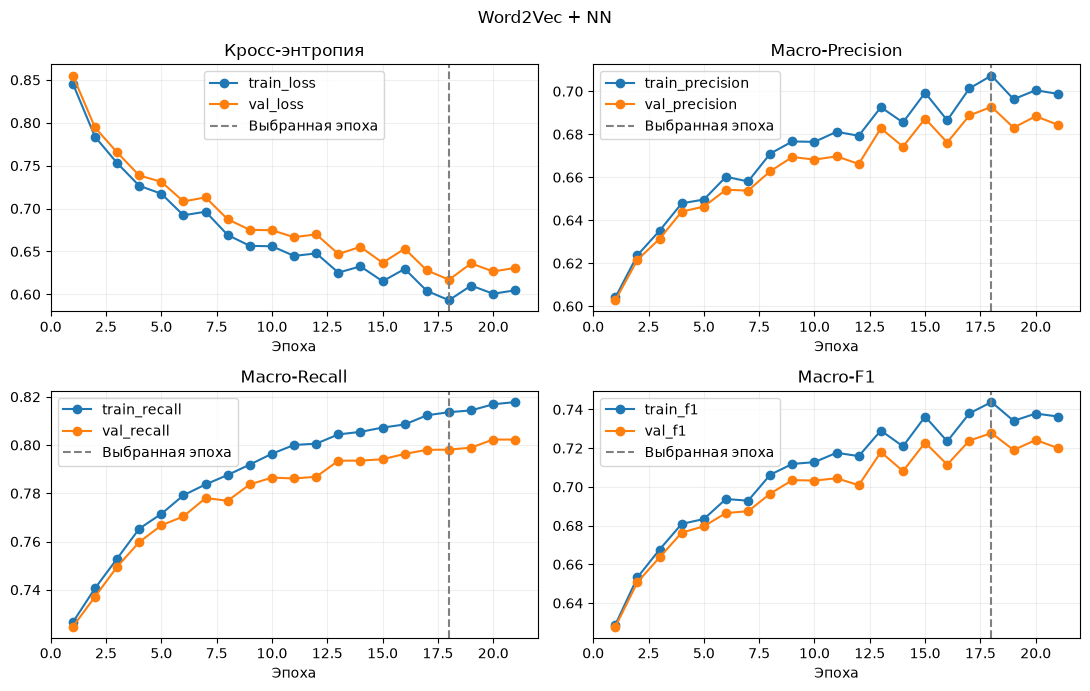

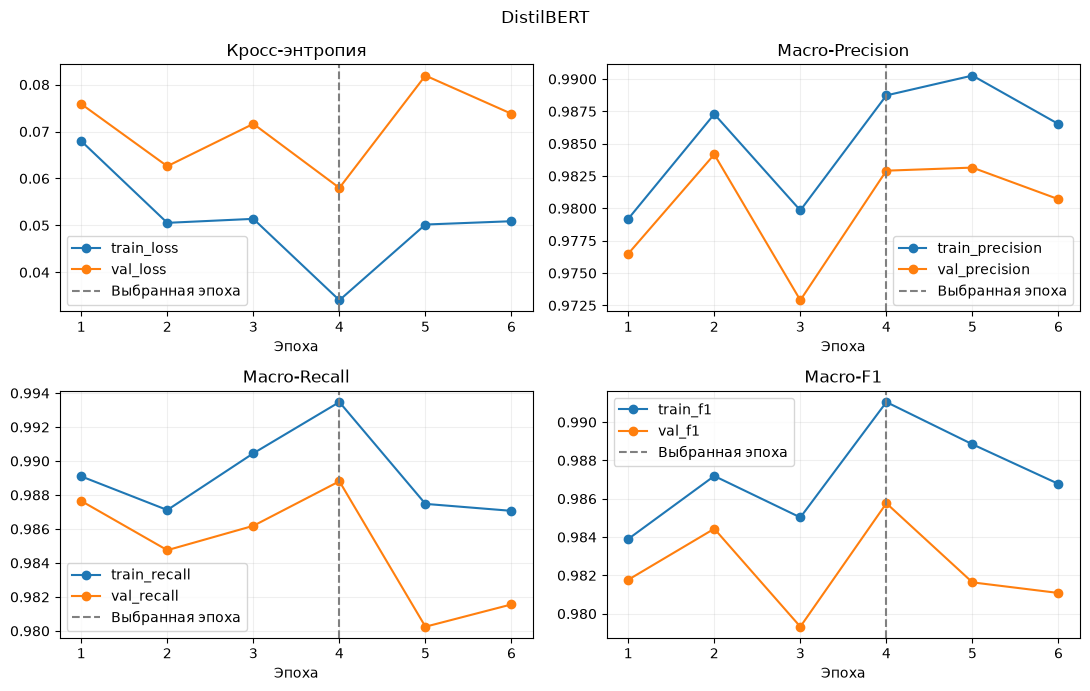

In [53]:
# Для каждой сети показываем реальные train/validation метрики по эпохам.
for name, history, model in [
    ('Word2Vec + NN', history_w2v, model_w2v),
    ('DistilBERT', history_bert, model_bert)
]:
    fig, axes = plt.subplots(2, 2, figsize=(11, 7))

    for ax, metric, title in zip(
        axes.flat,
        ['loss', 'precision', 'recall', 'f1'],
        ['Кросс-энтропия', 'Macro-Precision', 'Macro-Recall', 'Macro-F1']
    ):
        history.plot(x='epoch', y=['train_' + metric, 'val_' + metric], ax=ax, marker='o')
        ax.axvline(model.best_epoch, color='gray', linestyle='--', label='Выбранная эпоха')
        ax.set_title(title)
        ax.set_xlabel('Эпоха')
        ax.grid(alpha=0.2)
        ax.legend()

    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

## 18. Сравнение на validation

Для каждой модели показываем Accuracy, Precision, Recall, F1 и Balanced accuracy.
Macro одинаково учитывает каждую эмоцию; weighted учитывает частоты классов.
Выбор параметров и модели ведём по validation Macro-F1. Все остальные
метрики помогают увидеть, за счёт каких классов получается результат.

In [43]:
val_predictions = {
    'TF-IDF + NB': model_nb.predict(x_val_tfidf),
    'Word2Vec + NN': evaluate_nn(model_w2v, x_val_w2v, y_val)[0],
    'DistilBERT': evaluate_bert(model_bert, bert_val_data)[0]
}

# Метрики train берём для тех весов, которые вернула лучшая эпоха.
train_scores = {
    'TF-IDF + NB': f1_score(y_train, model_nb.predict(x_train_tfidf), average='macro'),
    'Word2Vec + NN': history_w2v.iloc[model_w2v.best_epoch - 1]['train_f1'],
    'DistilBERT': history_bert.iloc[model_bert.best_epoch - 1]['train_f1']
}

rows = []
for name, prediction in val_predictions.items():
    row = {'Модель': name}
    row.update(get_metrics(y_val, prediction))
    row['F1 train'] = train_scores[name]
    row['Разрыв train/val'] = train_scores[name] - row['Macro-F1']
    rows.append(row)

results_df = pd.DataFrame(rows).rename(columns={
    'Accuracy': 'Accuracy (val)', 'Macro-F1': 'Macro-F1 (val)',
    'Balanced accuracy': 'Balanced accuracy (val)'
}).sort_values('Macro-F1 (val)', ascending=False)
baseline_f1 = f1_score(y_val, val_predictions['TF-IDF + NB'], average='macro')
results_df['Δ F1 к NB'] = results_df['Macro-F1 (val)'] - baseline_f1
best_name = results_df.iloc[0]['Модель']
display(results_df.round(4))
print('Выбрана по validation:', best_name)

# Контроль: какой результат даст постоянный ответ самым частым классом.
most_common_class = np.bincount(y_train).argmax()
majority_prediction = np.full(len(y_val), most_common_class)
print('Всегда предсказывать', class_names[most_common_class])
display(pd.DataFrame([get_metrics(y_val, majority_prediction)]).round(4))

,Модель,Accuracy (val),Macro-Precision,Macro-Recall,Macro-F1 (val),Weighted-Precision,Weighted-Recall,Weighted-F1,Balanced accuracy (val),F1 train,Разрыв train/val,Δ F1 к NB
2,DistilBERT,0.9901,0.9829,0.9888,0.9858,0.9902,0.9901,0.9901,0.9888,0.9910,0.0053,0.1435
0,TF-IDF + NB,0.8895,0.9250,0.7913,0.8422,0.8957,0.8895,0.8865,0.7913,0.8907,0.0485,0.0000
1,Word2Vec + NN,0.7764,0.6928,0.7981,0.7278,0.8030,0.7764,0.7827,0.7981,0.7438,0.0160,-0.1145


Выбрана по validation: DistilBERT
Всегда предсказывать joy


,Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Weighted-Precision,Weighted-Recall,Weighted-F1,Balanced accuracy
0,0.3484,0.0581,0.1667,0.0861,0.1213,0.3484,0.18,0.1667


In [44]:
time_df = pd.DataFrame({
    'Модель': ['TF-IDF + NB', 'Word2Vec + NN', 'DistilBERT'],
    'Подготовка признаков, с': [tfidf_build_time, word2vec_time, np.nan],
    'Подбор, с': [tfidf_time + nb_time + nb_details_time, nn_search_time, bert_search_time],
    'Обучение сети, с': [np.nan, nn_time, bert_time]
})
display(time_df.round(1))

,Модель,"Подготовка признаков, с","Подбор, с","Обучение сети, с"
0,TF-IDF + NB,12.6,286.0,NaN
1,Word2Vec + NN,115.1,392.0,156.4
2,DistilBERT,NaN,21.1,8199.9


Время подбора показано отдельно от итогового обучения.
DistilBERT и выходной слой обучаются вместе. В таблицу не входит
время общей подготовки текста, токенизации и первой загрузки модели.

## 19. Качество каждой эмоции

Precision — какая доля предсказаний данного класса правильная.
Recall — какую долю его реальных примеров удалось найти.
F1 объединяет Precision и Recall.
В матрицах ошибок строки соответствуют реальным классам и нормированы до суммы 1.

TF-IDF + NB


,precision,recall,f1-score,support
anger,0.955,0.828,0.887,5204.0
fear,0.960,0.806,0.876,3934.0
joy,0.853,0.960,0.903,12874.0
love,0.946,0.643,0.765,2426.0
sadness,0.879,0.947,0.912,11539.0
surprise,0.957,0.564,0.710,980.0


Word2Vec + NN


,precision,recall,f1-score,support
anger,0.712,0.792,0.750,5204.0
fear,0.675,0.809,0.736,3934.0
joy,0.892,0.787,0.836,12874.0
love,0.571,0.810,0.670,2426.0
sadness,0.868,0.733,0.795,11539.0
surprise,0.438,0.858,0.580,980.0


DistilBERT


,precision,recall,f1-score,support
anger,0.984,0.985,0.985,5204.0
fear,0.986,0.973,0.979,3934.0
joy,0.993,0.996,0.995,12874.0
love,0.991,0.993,0.992,2426.0
sadness,0.995,0.991,0.993,11539.0
surprise,0.949,0.995,0.972,980.0


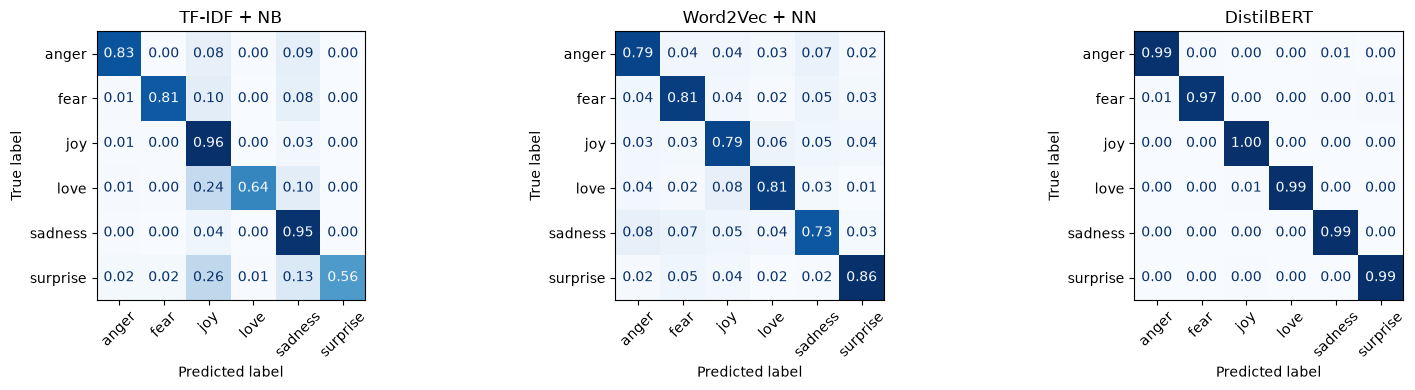

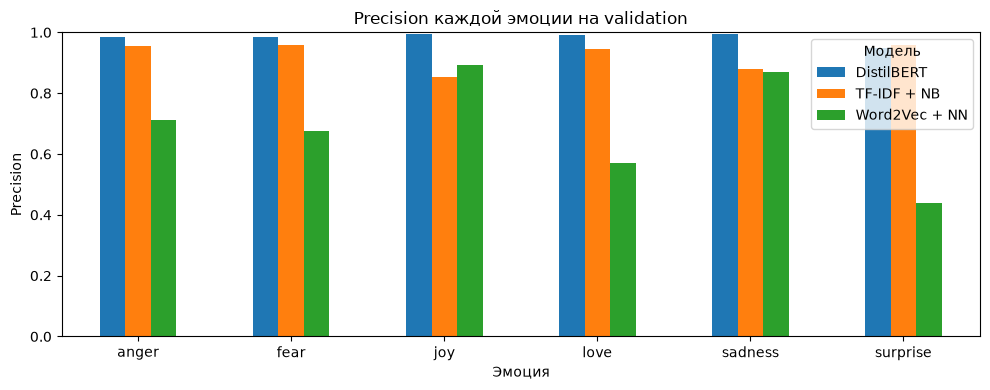

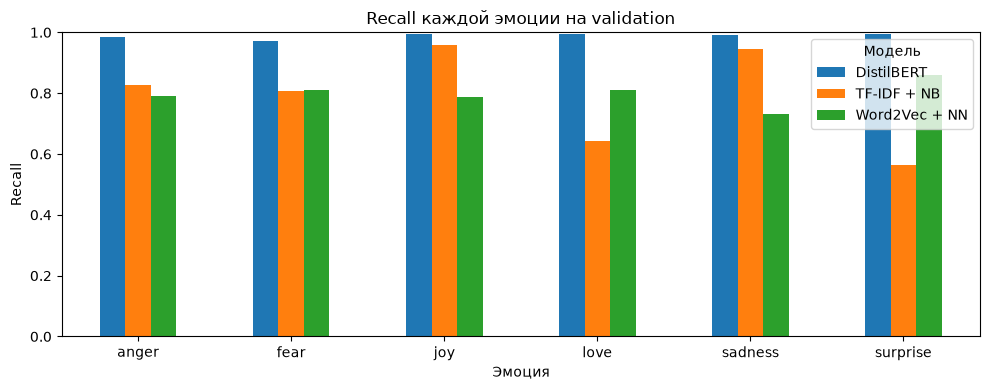

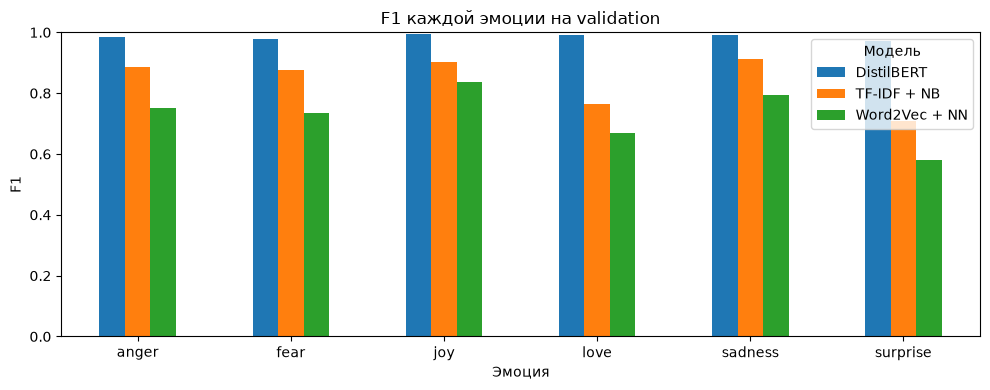

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
class_rows = []

for ax, (name, prediction) in zip(axes, val_predictions.items()):
    print(name)
    report = classification_report(
        y_val, prediction, labels=np.arange(class_count), target_names=class_names,
        output_dict=True, zero_division=0
    )
    display(pd.DataFrame(report).T.loc[class_names].round(3))

    for emotion in class_names:
        class_rows.append({
            'Модель': name, 'Эмоция': emotion,
            'Precision': report[emotion]['precision'],
            'Recall': report[emotion]['recall'],
            'F1': report[emotion]['f1-score']
        })

    ConfusionMatrixDisplay.from_predictions(
        y_val, prediction, labels=np.arange(class_count), display_labels=class_names,
        normalize='true', values_format='.2f', cmap='Blues',
        colorbar=False, xticks_rotation=45, ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

class_results = pd.DataFrame(class_rows)
for metric in ['Precision', 'Recall', 'F1']:
    class_results.pivot(index='Эмоция', columns='Модель', values=metric).plot.bar(figsize=(10, 4), rot=0)
    plt.ylabel(metric)
    plt.ylim(0, 1)
    plt.title(metric + ' каждой эмоции на validation')
    plt.tight_layout()
    plt.show()

### Какие эмоции модели предсказывают чаще

Сравним количество настоящих эмоций с количеством предсказаний каждой модели.
Если модель почти всегда выбирает один класс, это будет видно в таблице.
Метрики для каждой эмоции уже приведены в отчётах выше: support — число
настоящих текстов этого класса, а не количество предсказаний.

In [46]:
# В первой колонке — реальные классы, в остальных — ответы моделей.
prediction_counts = pd.DataFrame({'На самом деле': pd.Series(y_val).value_counts()})

for name, prediction in val_predictions.items():
    prediction_counts[name] = pd.Series(prediction).value_counts()

prediction_counts = prediction_counts.reindex(range(class_count)).fillna(0).astype(int)
prediction_counts.index = class_names
prediction_counts.index.name = 'Эмоция'
display(prediction_counts)

,На самом деле,TF-IDF + NB,Word2Vec + NN,DistilBERT
Эмоция,,,,
anger,5204,4509,5786,5212
fear,3934,3305,4713,3882
joy,12874,14495,11353,12911
love,2426,1648,3444,2432
sadness,11539,12422,9743,11493
surprise,980,578,1918,1027


## 20. Итоговый test

Все параметры зафиксированы. Сравниваем три решения на одном test.
Выбор лучшей модели остаётся основанным на validation.
После просмотра test не подбираем по нему настройки.

In [47]:
# Параметры уже выбраны. По этим результатам их больше не меняем.
test_predictions = {
    'TF-IDF + NB': model_nb.predict(x_test_tfidf),
    'Word2Vec + NN': evaluate_nn(model_w2v, x_test_w2v, y_test)[0],
    'DistilBERT': evaluate_bert(model_bert, bert_test_data)[0]
}

test_rows = []
for name, prediction in test_predictions.items():
    row = {'Модель': name}
    row.update(get_metrics(y_test, prediction))
    test_rows.append(row)

    print(name)
    print(classification_report(y_test, prediction, labels=np.arange(class_count),
                                target_names=class_names, digits=3, zero_division=0))

test_results = pd.DataFrame(test_rows).rename(columns={
    'Accuracy': 'Accuracy (test)', 'Macro-F1': 'Macro-F1 (test)',
    'Balanced accuracy': 'Balanced accuracy (test)'
})
display(test_results.round(4))
print('Модель, выбранная ранее по validation:', best_name)

majority_prediction = np.full(len(y_test), most_common_class)
print('Постоянный ответ самым частым классом:')
display(pd.DataFrame([get_metrics(y_test, majority_prediction)]).round(4))

TF-IDF + NB
              precision    recall  f1-score   support

       anger      0.959     0.844     0.898      5203
        fear      0.964     0.795     0.871      3935
         joy      0.851     0.964     0.904     12874
        love      0.944     0.651     0.771      2426
     sadness      0.882     0.939     0.910     11540
    surprise      0.969     0.575     0.722       979

    accuracy                          0.890     36957
   macro avg      0.928     0.795     0.846     36957
weighted avg      0.897     0.890     0.888     36957

Word2Vec + NN
              precision    recall  f1-score   support

       anger      0.713     0.785     0.747      5203
        fear      0.672     0.806     0.733      3935
         joy      0.892     0.789     0.837     12874
        love      0.583     0.829     0.684      2426
     sadness      0.865     0.733     0.794     11540
    surprise      0.451     0.872     0.595       979

    accuracy                          0.778     369

,Модель,Accuracy (test),Macro-Precision,Macro-Recall,Macro-F1 (test),Weighted-Precision,Weighted-Recall,Weighted-F1,Balanced accuracy (test)
0,TF-IDF + NB,0.8904,0.9280,0.7947,0.8458,0.8969,0.8904,0.8877,0.7947
1,Word2Vec + NN,0.7776,0.6960,0.8024,0.7317,0.8030,0.7776,0.7834,0.8024
2,DistilBERT,0.9910,0.9855,0.9896,0.9875,0.9911,0.9910,0.9910,0.9896


Модель, выбранная ранее по validation: DistilBERT
Постоянный ответ самым частым классом:


,Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Weighted-Precision,Weighted-Recall,Weighted-F1,Balanced accuracy
0,0.3484,0.0581,0.1667,0.0861,0.1213,0.3484,0.18,0.1667


## 21. Разбор ошибок

Смотрим исходные и подготовленные тексты, пары перепутанных эмоций
и доли ошибок разных классов. Это помогает сформулировать гипотезы:
неоднозначная разметка, смешение эмоций, сложные отрицания, потеря порядка в Word2Vec.
Несогласие модели с меткой само по себе не доказывает ошибку разметки.

In [48]:
errors = test_df[['text', 'clean_text', 'prepared_text', 'emotion']].copy()
errors['Предсказано'] = encoder.inverse_transform(test_predictions[best_name])
errors = errors[errors['emotion'] != errors['Предсказано']]
print('Ошибок:', len(errors), 'из', len(test_df))
with pd.option_context('display.max_colwidth', 180):
    display(errors.head(10))
confusion_pairs = errors.groupby(['emotion', 'Предсказано']).size().sort_values(ascending=False)
display(confusion_pairs.head(10).rename('Количество'))

error_rates = pd.DataFrame({
    'Количество': test_df['emotion'].value_counts(),
    'Ошибок': errors['emotion'].value_counts()
}).fillna(0)
error_rates['Доля ошибок'] = error_rates['Ошибок'] / error_rates['Количество']
display(error_rates.round(3))

Ошибок: 331 из 36957


,text,clean_text,prepared_text,emotion,Предсказано
225694,when two drug addicts tried to take away my money,when two drug addicts tried to take away my money,when two drug addict try to take away my money,fear,anger
82984,i was to be given an audition to get a role i had a competitress and i wasnt well prepared because i was ill,i was to be given an audition to get a role i had a competitress and i was not well prepared because i was ill,i be to be give an audition to get a role i have a competitress and i be not not_well prepared because i be ill,fear,sadness
33498,my mother was stuck by an apoplectic fit,my mother was stuck by an apoplectic fit,my mother be stick by an apoplectic fit,sadness,fear
104267,a relative,a relative,a relative,sadness,fear
193536,the day i got to know that i would get a shared dwelling with my boyfriend my parents place was getting a little crowded with my growing bother wanting a room to himself i firs...,the day i got to know that i would get a shared dwelling with my boyfriend my parents place was getting a little crowded with my growing bother wanting a room to himself i firs...,the day i get to know that i would get a share dwelling with my boyfriend my parent place be get a little crowded with my grow bother want a room to himself i first felt doubt,joy,anger
103272,i feel so much pressure to say something valuable and then feel vain spending so much time trying to produce somethin,i feel so much pressure to say something valuable and then feel vain spending so much time trying to produce somethin,i feel so much pressure to say something valuable and then feel vain spend so much time try to produce somethin,joy,sadness
197004,i called blake who rushed home from his worksite twenty minutes away and just as he arrived sarah and amelie popped in and saved the day in sarahs calm can do manner which was ...,i called blake who rushed home from his worksite twenty minutes away and just as he arrived sarah and amelie popped in and saved the day in sarahs calm can do manner which was ...,i call blake who rush home from his worksite twenty minute away and just a he arrive sarah and amelie pop in and save the day in sarahs calm can do manner which be wonderful bu...,sadness,joy
123527,when somebody broke into our home one night when my mother was out,when somebody broke into our home one night when my mother was out,when somebody break into our home one night when my mother be out,fear,sadness
233682,when i got low marks in bsc final,when i got low marks in bsc final,when i get low mark in bsc final,anger,joy
10592,when my boyfriend went away for a month long holiday without me,when my boyfriend went away for a month long holiday without me,when my boyfriend go away for a month long holiday without without_me,anger,joy


emotion  Предсказано
sadness  anger          32
fear     surprise       30
sadness  joy            29
fear     anger          27
anger    joy            26
joy      sadness        25
anger    fear           21
fear     sadness        20
anger    sadness        20
sadness  fear           19
Name: Количество, dtype: int64

,Количество,Ошибок,Доля ошибок
emotion,,,
anger,5203,75,0.014
fear,3935,89,0.023
joy,12874,52,0.004
love,2426,12,0.005
sadness,11540,95,0.008
surprise,979,8,0.008


## 22. Проверка своего текста

Повторяем те же преобразования в том же порядке.
DistilBERT получает форму до лемматизации, классические признаки — после неё.
Softmax применяется к логитам нейросетей для получения вероятностей.

In [49]:
my_text = "I am not happy about this :("
normalized = my_text.lower().replace('’', "'")
normalized = replace_emotions(normalized)
normalized = expand_contractions(normalized)
normalized = clean_links(normalized)
prepared = clean_letters(normalized)
prepared = lemmatize_text(prepared)
prepared = join_negations(prepared)
print('Для BERT:', normalized)
print('Для TF-IDF и Word2Vec:', prepared)

nb_prediction = model_nb.predict(vectorizer.transform([prepared]))[0]
features = scaler.transform(text_vector(prepared).reshape(1, -1)).astype(np.float32)
model_w2v.eval()
model_bert.eval()
with torch.no_grad():
    w2v_probabilities = torch.softmax(model_w2v(torch.from_numpy(features).to(device)), dim=1)
    encoded = tokenizer(normalized, truncation=True, max_length=MAX_LENGTH, return_tensors='pt').to(device)
    bert_probabilities = torch.softmax(model_bert(**encoded).logits, dim=1)
print('TF-IDF + NB:', class_names[nb_prediction])
print('Word2Vec + NN:', class_names[w2v_probabilities.argmax().item()])
print('DistilBERT:', class_names[bert_probabilities.argmax().item()])

Для BERT: i am not happy about this sad face
Для TF-IDF и Word2Vec: i be not not_happy about this sad face
TF-IDF + NB: sadness
Word2Vec + NN: joy
DistilBERT: sadness


## Источники

- [Emotion: данные и описание](https://huggingface.co/datasets/dair-ai/emotion)
- [CARER: статья о наборе данных](https://aclanthology.org/D18-1404/)
- [contractions](https://github.com/kootenpv/contractions)
- [emoji](https://emoji-python.readthedocs.io/)
- [WordNetLemmatizer](https://www.nltk.org/api/nltk.stem.wordnet.html)
- [Word2Vec](https://radimrehurek.com/gensim/models/word2vec.html)
- [MultinomialNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html)
- [DistilBERT: модель](https://huggingface.co/distilbert/distilbert-base-uncased)
- [DistilBERT: документация](https://huggingface.co/docs/transformers/model_doc/distilbert)
- [CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)

## 23. Заключение

Следующая ячейка формирует вывод из результатов текущего запуска.
Сравниваем TF-IDF + NB, Word2Vec + нейросеть и дообученный DistilBERT
на общих выборках. Параметры выбираем по validation, а test используем
для итоговой оценки. Веса классов и macro-метрики учитывают дисбаланс.

Ограничения: автоматическая разметка, один seed, небольшой перебор параметров,
потеря порядка при усреднении Word2Vec и ограничение DistilBERT по длине.
Пробный запуск на части данных не заменяет итоговый эксперимент.

In [ ]:
class_counts = df['emotion'].value_counts()
imbalance_ratio = class_counts.max() / class_counts.min()

best_val = results_df.set_index('Модель').loc[best_name]
best_test = test_results.set_index('Модель').loc[best_name]
epochs_w2v = model_w2v.best_epoch
epochs_bert = model_bert.best_epoch
report = classification_report(y_test, test_predictions[best_name],
                               target_names=class_names, output_dict=True, zero_division=0)
weakest = min(class_names, key=lambda name: report[name]['f1-score'])
mode = 'Полный корпус после очистки' if DATA_LIMIT is None else 'Пробный ограниченный запуск'

class_counts = train_df['emotion'].value_counts()
imbalance_ratio = class_counts.max() / class_counts.min()

conclusion_text = f"""
**{mode}: {len(df):,} текстов.**
Train — {len(train_df):,}, validation — {len(val_df):,}, test — {len(test_df):,}.
Самый частый класс встречается в {imbalance_ratio:.2f} раза чаще редкого.

По validation выбрана **{best_name}**: Macro-F1 **{best_val['Macro-F1 (val)']:.4f}**,
разница с настроенным NB **{best_val['Δ F1 к NB']:+.4f}**.
На test: Accuracy **{best_test['Accuracy (test)']:.4f}**,
Macro-F1 **{best_test['Macro-F1 (test)']:.4f}**,
Macro-Precision **{best_test['Macro-Precision']:.4f}**,
Macro-Recall **{best_test['Macro-Recall']:.4f}**,
Balanced accuracy **{best_test['Balanced accuracy (test)']:.4f}**.
Разрыв train/validation F1: **{best_val['Разрыв train/val']:.4f}**.
Оцениваем его вместе с графиками потерь и F1, а не как самостоятельное доказательство.

Подбор NB: alpha = **{best_alpha}**.
Word2Vec: размер вектора **{best_vector_size}**, окно **{best_window}**.
Нейросеть: **{best_hidden}** нейронов, learning rate **{best_lr}**.
DistilBERT: learning rate **{best_bert_lr}**.
Восстановленные лучшие эпохи: NN — **{epochs_w2v}**, DistilBERT — **{epochs_bert}**.
Эти результаты относятся к ограниченному перебору параметров.

Ошибок выбранной модели: **{len(errors)} из {len(test_df)}**.
Самый трудный класс на test — **{weakest}**,
F1 **{report[weakest]['f1-score']:.4f}**, Recall **{report[weakest]['recall']:.4f}**.
Примеры и направления ошибок приведены выше и требуют содержательного разбора.
При оценке практической пригодности учитываем также время обучения из таблицы
"""
display(Markdown(conclusion_text))

for name, history, model in [('Word2Vec + NN', history_w2v, model_w2v), ('DistilBERT', history_bert, model_bert)]:
    print(name, ': выполнено эпох', len(history), ', выбрана эпоха', model.best_epoch)
    if model.best_epoch == len(history):
        print('Лучшая эпоха последняя: можно проверить дополнительное обучение по validation.')
    else:
        print('Дальнейшие эпохи не улучшили validation F1; возвращены лучшие веса.')
    print('Окончательный вывод о переобучении делаем по потерям, Precision, Recall и F1 вместе.')